# Simulation-Based A/B Testing — E-Commerce Conversion Analysis

## Objective
This notebook demonstrates a reproducible, simulation-based A/B testing workflow using historical e-commerce user behaviour.

**Important experimental boundary**
- Historical behaviour is loaded from the project sample (`new_file.csv`).
- Eligible users are users with at least one `view` event and no `purchase` event in the observed sample.
- Eligible users are assigned to simulated Control and Treatment groups using pseudo-random allocation.
- No coupon was actually sent, and no post-intervention purchase was observed.
- The binary outcome is synthetically generated using predefined probabilities (1.7% for Control and 2.4% for Treatment).

Therefore, the comparison is a **simulation exercise**, not evidence from a live randomized controlled trial and not a causal estimate of an actual coupon campaign.

## Reproducibility
The random seed is fixed. Re-running the notebook with the same input data and package versions should reproduce the same allocation and simulated outcomes.

## 1. Load and validate historical user behaviour

The input is the project sample exported as `new_file.csv`. The notebook uses user-level eligibility: a user must have viewed at least one product and must not have generated a purchase event in the observed sample.

This eligibility rule does not mean that the user was observed after receiving a coupon. The later outcome is generated synthetically in Section 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep

DATA_PATH = "new_file.csv"
RANDOM_SEED = 42

df = pd.read_csv(DATA_PATH)

required_columns = {"user_id", "event_type"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

# Exclude records without a usable user identifier or event type.
df = df.dropna(subset=["user_id", "event_type"]).copy()
df["event_type"] = df["event_type"].astype(str).str.lower().str.strip()

print(f"Event records: {len(df):,}")
print(f"Unique users: {df['user_id'].nunique():,}")
print("\\nEvent counts:")
print(df["event_type"].value_counts())

Event records: 3,000,000
Unique users: 410,609
\nEvent counts:
event_type
view        2904210
purchase      50802
cart          44988
Name: count, dtype: int64


## 2. Define eligible users

User-level historical indicators are created from the events in the observed sample.

Eligibility:
- `viewed = 1`: at least one view event.
- `purchased = 0`: no purchase event in the observed sample.

The `carted` indicator is retained for descriptive balance checks only. It is not used to define eligibility.

In [2]:
user_behavior = (
    df.assign(
        viewed_event=df["event_type"].eq("view"),
        cart_event=df["event_type"].eq("cart"),
        purchase_event=df["event_type"].eq("purchase")
    )
    .groupby("user_id", as_index=False)
    .agg(
        viewed=("viewed_event", "max"),
        carted=("cart_event", "max"),
        purchased=("purchase_event", "max")
    )
)

for col in ["viewed", "carted", "purchased"]:
    user_behavior[col] = user_behavior[col].astype(int)

target_users = user_behavior.loc[
    (user_behavior["viewed"] == 1) &
    (user_behavior["purchased"] == 0)
].copy()

if target_users.empty:
    raise ValueError("No eligible users were found. Check the input sample and eligibility criteria.")

print(f"Total unique users: {len(user_behavior):,}")
print(f"Eligible users: {len(target_users):,}")
print(f"Eligibility rate: {len(target_users) / len(user_behavior):.2%}")

display(target_users.head())

Total unique users: 410,609
Eligible users: 377,120
Eligibility rate: 91.84%


,user_id,viewed,carted,purchased
0,183503497,1,0,0
1,241587569,1,0,0
2,244951053,1,0,0
3,255544096,1,0,0
4,260013793,1,0,0


## 3. Simulate group assignment and purchase outcomes

Eligible users are randomly assigned approximately 50:50 to Control and Treatment. The allocation is pseudo-random and reproducible.

Synthetic purchase outcomes are then generated using the assumptions below:
- Control conversion probability: 1.7%.
- Treatment conversion probability: 2.4%.

These probabilities are **inputs to the simulation**, not conversion rates measured from a real intervention.

In [3]:
CONTROL_PROBABILITY = 0.017
TREATMENT_PROBABILITY = 0.024

rng = np.random.default_rng(RANDOM_SEED)

target_users = target_users.reset_index(drop=True)
target_users["group"] = rng.choice(
    ["control", "treatment"],
    size=len(target_users),
    p=[0.5, 0.5]
)

target_users["simulated_purchase"] = 0

control_mask = target_users["group"].eq("control")
treatment_mask = target_users["group"].eq("treatment")

target_users.loc[control_mask, "simulated_purchase"] = rng.binomial(
    1, CONTROL_PROBABILITY, size=int(control_mask.sum())
)
target_users.loc[treatment_mask, "simulated_purchase"] = rng.binomial(
    1, TREATMENT_PROBABILITY, size=int(treatment_mask.sum())
)

target_users["simulated_purchase"] = target_users["simulated_purchase"].astype(int)

print("Group allocation:")
print(target_users["group"].value_counts())
print("\\nSimulated outcomes:")
print(
    target_users.groupby("group")["simulated_purchase"]
    .agg(sample_size="count", simulated_purchases="sum", conversion_rate="mean")
)

Group allocation:
group
treatment    188578
control      188542
Name: count, dtype: int64
\nSimulated outcomes:
           sample_size  simulated_purchases  conversion_rate
group                                                       
control         188542                 3211         0.017031
treatment       188578                 4497         0.023847


## 4. Experimental design audit

This section checks allocation balance, historical behaviour balance and eligibility consistency. It does not validate a real-world intervention because no intervention was delivered.

In [4]:
group_audit = (
    target_users.groupby("group")
    .agg(
        sample_size=("user_id", "size"),
        simulated_purchases=("simulated_purchase", "sum"),
        simulated_conversion=("simulated_purchase", "mean"),
        historical_view_rate=("viewed", "mean"),
        historical_cart_rate=("carted", "mean"),
        historical_purchase_rate=("purchased", "mean")
    )
)

print("Group-level audit:")
display(group_audit)

print("Allocation proportions:")
display(target_users["group"].value_counts(normalize=True).rename("allocation_share"))

assert target_users["viewed"].eq(1).all(), "Eligibility error: a non-viewer entered the sample."
assert target_users["purchased"].eq(0).all(), "Eligibility error: a historical purchaser entered the sample."
assert set(target_users["group"].unique()) == {"control", "treatment"}

print("Eligibility checks passed.")

Group-level audit:


,sample_size,simulated_purchases,simulated_conversion,historical_view_rate,historical_cart_rate,historical_purchase_rate
group,,,,,,
control,188542,3211,0.017031,1.0,0.021619,0.0
treatment,188578,4497,0.023847,1.0,0.021514,0.0


Allocation proportions:


group
treatment    0.500048
control      0.499952
Name: allocation_share, dtype: float64

Eligibility checks passed.


## 5. Calculate simulated conversion rates and uplift

The primary outcome is the proportion of eligible users with a simulated purchase outcome equal to 1.

- **Absolute uplift** is the percentage-point difference.
- **Relative uplift** is the absolute difference divided by the Control rate.

Both metrics describe the generated simulation only.

In [5]:
control = target_users.loc[
    target_users["group"].eq("control"), "simulated_purchase"
]
treatment = target_users.loc[
    target_users["group"].eq("treatment"), "simulated_purchase"
]

n_control = int(control.size)
n_treatment = int(treatment.size)
x_control = int(control.sum())
x_treatment = int(treatment.sum())

if n_control == 0 or n_treatment == 0:
    raise ValueError("Both groups must contain at least one eligible user.")

control_rate = x_control / n_control
treatment_rate = x_treatment / n_treatment
absolute_uplift = treatment_rate - control_rate
relative_uplift = absolute_uplift / control_rate if control_rate > 0 else np.nan

summary = pd.DataFrame({
    "Group": ["Control", "Treatment"],
    "Users": [n_control, n_treatment],
    "Simulated Purchases": [x_control, x_treatment],
    "Simulated Conversion Rate": [control_rate, treatment_rate]
})

display(summary.style.format({"Simulated Conversion Rate": "{:.4%}"}))

print(f"Absolute uplift: {absolute_uplift:.4%} ({absolute_uplift*100:.3f} percentage points)")
print(f"Relative uplift: {relative_uplift:.2%}")

,Group,Users,Simulated Purchases,Simulated Conversion Rate
0,Control,188542,3211,1.7031%
1,Treatment,188578,4497,2.3847%


Absolute uplift: 0.6816% (0.682 percentage points)
Relative uplift: 40.02%


## 6. Two-proportion Z-test

A two-proportion Z-test is used to compare the two binary simulated conversion outcomes.

- H₀: the two simulated conversion proportions are equal.
- H₁: the two simulated conversion proportions differ.

The p-value tests the difference in the **synthetically generated outcomes**. Statistical significance does not turn the simulation into evidence of a real coupon effect.

In [6]:
pooled_rate = (x_control + x_treatment) / (n_control + n_treatment)

se_null = np.sqrt(
    pooled_rate * (1 - pooled_rate) *
    (1 / n_control + 1 / n_treatment)
)

if se_null == 0:
    z_statistic = np.nan
    p_value = np.nan
else:
    z_statistic = absolute_uplift / se_null
    p_value = 2 * norm.sf(abs(z_statistic))

print("========== Two-Proportion Z-Test ==========")
print(f"Control:   {x_control:,} / {n_control:,} = {control_rate:.4%}")
print(f"Treatment: {x_treatment:,} / {n_treatment:,} = {treatment_rate:.4%}")
print(f"Z-statistic: {z_statistic:.4f}")
print(f"P-value: {p_value:.6e}")

if pd.notna(p_value):
    print("Statistical decision at alpha=0.05:",
          "Reject H0" if p_value < 0.05 else "Fail to reject H0")

========== Two-Proportion Z-Test ==========
Control:   3,211 / 188,542 = 1.7031%
Treatment: 4,497 / 188,578 = 2.3847%
Z-statistic: 14.7913
P-value: 1.667453e-49
Statistical decision at alpha=0.05: Reject H0


## 7. Visualize simulated conversion rates

This chart compares the simulated purchase conversion rates. It is deliberately not labelled as a measured campaign funnel.

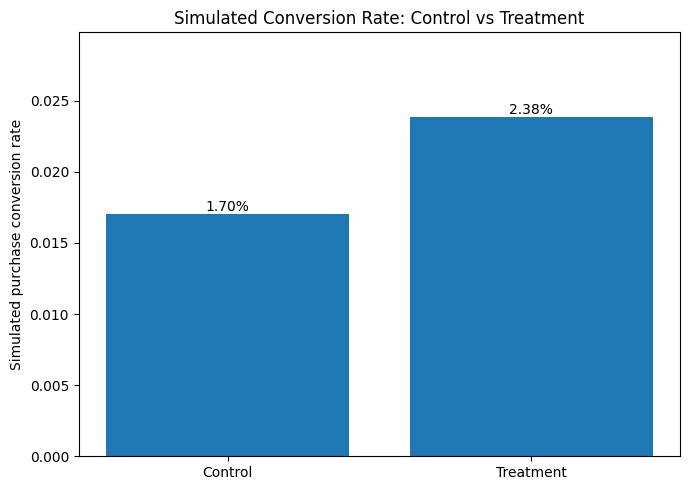

In [7]:
rates = [control_rate, treatment_rate]
labels = ["Control", "Treatment"]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, rates)
ax.set_ylabel("Simulated purchase conversion rate")
ax.set_title("Simulated Conversion Rate: Control vs Treatment")
ax.set_ylim(0, max(rates) * 1.25 if max(rates) > 0 else 1)

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.2%}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 8. Wilson confidence intervals for each group

Wilson score intervals are calculated separately for the two simulated proportions. These intervals quantify sampling uncertainty under the binomial model for the generated outcomes.

In [8]:
control_ci = proportion_confint(
    count=x_control, nobs=n_control, alpha=0.05, method="wilson"
)
treatment_ci = proportion_confint(
    count=x_treatment, nobs=n_treatment, alpha=0.05, method="wilson"
)

group_ci = pd.DataFrame({
    "Group": ["Control", "Treatment"],
    "Conversion Rate": [control_rate, treatment_rate],
    "CI Lower": [control_ci[0], treatment_ci[0]],
    "CI Upper": [control_ci[1], treatment_ci[1]]
})

display(group_ci.style.format({
    "Conversion Rate": "{:.4%}",
    "CI Lower": "{:.4%}",
    "CI Upper": "{:.4%}"
}))

,Group,Conversion Rate,CI Lower,CI Upper
0,Control,1.7031%,1.6456%,1.7625%
1,Treatment,2.3847%,2.3168%,2.4545%


## 9. Confidence interval for the absolute difference

The Newcombe-Wilson method is used for a confidence interval for the difference between two independent proportions. A Wald interval is also shown as a simple comparison.

In [9]:
# Wald interval for treatment minus control
se_difference = np.sqrt(
    control_rate * (1 - control_rate) / n_control +
    treatment_rate * (1 - treatment_rate) / n_treatment
)
wald_ci = (
    absolute_uplift - 1.96 * se_difference,
    absolute_uplift + 1.96 * se_difference
)

# Newcombe-Wilson interval for treatment minus control
newcombe_ci = confint_proportions_2indep(
    count1=x_treatment,
    nobs1=n_treatment,
    count2=x_control,
    nobs2=n_control,
    method="newcomb",
    compare="diff",
    alpha=0.05
)

print(f"Absolute uplift: {absolute_uplift:.4%}")
print(f"Wald 95% CI: [{wald_ci[0]:.4%}, {wald_ci[1]:.4%}]")
print(f"Newcombe-Wilson 95% CI: [{newcombe_ci[0]:.4%}, {newcombe_ci[1]:.4%}]")
print(
    "Newcombe-Wilson interval excludes zero:",
    bool(newcombe_ci[0] > 0 or newcombe_ci[1] < 0)
)

Absolute uplift: 0.6816%
Wald 95% CI: [0.5913%, 0.7719%]
Newcombe-Wilson 95% CI: [0.5914%, 0.7720%]
Newcombe-Wilson interval excludes zero: True


## 10. Illustrative revenue impact scenario

This section translates the simulated uplift into an illustrative scenario. It is **not a forecast or realized revenue result**.

The source project records:
- Purchase-event revenue: 16,316,897.45
- Purchase events: 50,802

Their ratio is an average purchase-event value, not necessarily order-level Average Order Value (AOV). The scenario assumes, purely for illustration, that each additional simulated buyer generates one purchase event at this historical average value. It does not account for coupon cost, cannibalization, natural conversion, repeat events or operational constraints.

In [10]:
eligible_users = len(target_users)

historical_purchase_event_revenue = 16_316_897.45
historical_purchase_events = 50_802

if historical_purchase_events <= 0:
    raise ValueError("Historical purchase event count must be positive.")

average_purchase_event_value = (
    historical_purchase_event_revenue / historical_purchase_events
)

estimated_additional_buyers = eligible_users * absolute_uplift
illustrative_incremental_value = (
    estimated_additional_buyers * average_purchase_event_value
)

scenario_summary = pd.DataFrame({
    "Metric": [
        "Eligible users in simulation",
        "Absolute simulated uplift",
        "Average historical purchase-event value",
        "Illustrative additional buyers",
        "Illustrative incremental purchase-event value"
    ],
    "Value": [
        eligible_users,
        absolute_uplift,
        average_purchase_event_value,
        estimated_additional_buyers,
        illustrative_incremental_value
    ]
})

display(scenario_summary)

print(
    "Interpretation: this is an assumption-based scenario derived from "
    "simulated uplift, not observed incremental GMV."
)

,Metric,Value
0,Eligible users in simulation,377120.000000
1,Absolute simulated uplift,0.006816
2,Average historical purchase-event value,321.186124
3,Illustrative additional buyers,2570.528407
4,Illustrative incremental purchase-event value,825618.054579


Interpretation: this is an assumption-based scenario derived from simulated uplift, not observed incremental GMV.


## 11. Final interpretation and limitations

### What this analysis demonstrates
1. Historical e-commerce behaviour can be used to define an eligible user population.
2. Eligible users can be assigned reproducibly to simulated groups.
3. Binary simulated outcomes can be compared using a two-proportion test.
4. Conversion differences can be reported with Wilson and Newcombe-Wilson confidence intervals.
5. A transparent, assumption-based revenue scenario can illustrate how an uplift might translate into monetary value.

### What this analysis does not demonstrate
1. No actual coupon was delivered to users.
2. No actual post-coupon purchases were observed.
3. The conversion probabilities were predefined by the analyst.
4. The observed difference is therefore driven by the simulation design and random outcome generation.
5. The p-value and confidence intervals do not establish the causal effectiveness of a real coupon campaign.
6. The revenue scenario is not realized GMV and should not be presented as a production forecast.

### Recommended wording for a portfolio
> A simulation-based A/B testing workflow was developed using historical e-commerce user behaviour. Eligible users were pseudo-randomly assigned to Control and Treatment groups, and post-intervention purchase outcomes were synthetically generated using predefined conversion probabilities. Two-proportion testing and confidence interval estimation were used to demonstrate the statistical evaluation workflow.

### Suggested next step for a real experiment
A live experiment would require a documented treatment (actual coupon exposure), persistent random assignment, a defined observation window, outcome tracking after assignment, and checks for sample-ratio mismatch and contamination.

In [11]:

# Phase 1.9.1.4 — Restored Dataset Revalidation

print("========== RESTORED DATA VALIDATION ==========")

print("Event records:", f"{len(df):,}")
print("All unique users:", f"{df['user_id'].nunique():,}")

print("\nEvent distribution:")
display(df["event_type"].value_counts().to_frame("event_count"))

print("\nUser behavior records:", f"{len(user_behavior):,}")
print("View users:", f"{user_behavior['viewed'].sum():,}")

print("\nEligible users:", f"{len(target_users):,}")

print("\nEligibility rate:")
print(f"{len(target_users) / len(user_behavior):.2%}")

print("\n========== VALIDATION ==========")

assert len(df) == 3_000_000
assert df["user_id"].nunique() == 410_609
assert len(user_behavior) == 410_609
assert user_behavior["viewed"].sum() == 410_574
assert len(target_users) == 377_120

print("Restored dataset: PASS")
print("User population: PASS")
print("Eligibility population: PASS")

print("\nPhase 1.9.1.4: PASS")


========== RESTORED DATA VALIDATION ==========
Event records: 3,000,000
All unique users: 410,609

Event distribution:


,event_count
event_type,
view,2904210
purchase,50802
cart,44988



User behavior records: 410,609
View users: 410,574

Eligible users: 377,120

Eligibility rate:
91.84%

========== VALIDATION ==========
Restored dataset: PASS
User population: PASS
Eligibility population: PASS

Phase 1.9.1.4: PASS


In [12]:

# Phase 1.9.2 — Experiment Dataset Rebuild Validation

# 1. Configuration
assert RANDOM_SEED == 42
assert CONTROL_PROBABILITY == 0.017
assert TREATMENT_PROBABILITY == 0.024

# 2. Population
assert len(target_users) == 377120
assert target_users["user_id"].is_unique

# 3. Group assignment
group_counts = (
    target_users["group"]
    .value_counts()
    .reindex(["control", "treatment"], fill_value=0)
)

assert group_counts.sum() == 377120

# 4. Outcome validation
assert target_users["simulated_purchase"].notna().all()
assert set(
    target_users["simulated_purchase"].unique()
).issubset({0, 1})

# 5. Build fresh experiment summary
experiment_summary_rebuilt = (
    target_users.groupby("group")
    .agg(
        users=("user_id", "nunique"),
        simulated_purchases=("simulated_purchase", "sum"),
        conversion_rate=("simulated_purchase", "mean")
    )
    .reindex(["control", "treatment"])
    .reset_index()
)

experiment_summary_rebuilt["conversion_rate_pct"] = (
    experiment_summary_rebuilt["conversion_rate"] * 100
)

print("========== EXPERIMENT DATASET VALIDATION ==========")

print("\nGroup allocation:")
display(group_counts.to_frame("users"))

print("\nExperiment summary:")
display(experiment_summary_rebuilt)

print("\nTotal users:", target_users["user_id"].nunique())
print(
    "Total simulated purchases:",
    target_users["simulated_purchase"].sum()
)

print("\nPhase 1.9.2: PASS")


========== EXPERIMENT DATASET VALIDATION ==========

Group allocation:


,users
group,
control,188542
treatment,188578



Experiment summary:


,group,users,simulated_purchases,conversion_rate,conversion_rate_pct
0,control,188542,3211,0.017031,1.703069
1,treatment,188578,4497,0.023847,2.384690



Total users: 377120
Total simulated purchases: 7708

Phase 1.9.2: PASS


In [13]:

# Phase 1.9.3 — Experiment Metrics Recalculation

from scipy.stats import norm
import numpy as np
import pandas as pd

# Extract group-level counts
summary = experiment_summary_rebuilt.set_index("group")

n_control = int(summary.loc["control", "users"])
x_control = int(summary.loc["control", "simulated_purchases"])

n_treatment = int(summary.loc["treatment", "users"])
x_treatment = int(summary.loc["treatment", "simulated_purchases"])

# Conversion rates
p_control = x_control / n_control
p_treatment = x_treatment / n_treatment

# Absolute and relative uplift
absolute_uplift = p_treatment - p_control
relative_uplift = absolute_uplift / p_control

# Two-proportion pooled Z-test
pooled_rate = (
    x_control + x_treatment
) / (
    n_control + n_treatment
)

standard_error = np.sqrt(
    pooled_rate * (1 - pooled_rate) *
    (1 / n_control + 1 / n_treatment)
)

z_statistic = absolute_uplift / standard_error

p_value = 2 * norm.sf(abs(z_statistic))

alpha = 0.05

decision = (
    "Reject H0"
    if p_value < alpha
    else "Fail to reject H0"
)

# Results table
experiment_metrics = pd.DataFrame({
    "metric": [
        "Control Conversion",
        "Treatment Conversion",
        "Absolute Uplift",
        "Relative Uplift",
        "Z Statistic",
        "P Value",
        "Alpha",
        "Statistical Decision"
    ],
    "value": [
        p_control,
        p_treatment,
        absolute_uplift,
        relative_uplift,
        z_statistic,
        p_value,
        alpha,
        decision
    ]
})

print("========== EXPERIMENT METRICS ==========")
display(experiment_metrics)

print("\n========== KEY RESULTS ==========")
print(f"Control Conversion: {p_control:.4%}")
print(f"Treatment Conversion: {p_treatment:.4%}")
print(f"Absolute Uplift: {absolute_uplift:.4%}")
print(f"Relative Uplift: {relative_uplift:.2%}")
print(f"Z Statistic: {z_statistic:.4f}")
print(f"P Value: {p_value:.6e}")
print(f"Decision: {decision}")

print("\nPhase 1.9.3: PASS")


========== EXPERIMENT METRICS ==========


,metric,value
0,Control Conversion,0.017031
1,Treatment Conversion,0.023847
2,Absolute Uplift,0.006816
3,Relative Uplift,0.400231
4,Z Statistic,14.791283
5,P Value,0.0
6,Alpha,0.05
7,Statistical Decision,Reject H0



========== KEY RESULTS ==========
Control Conversion: 1.7031%
Treatment Conversion: 2.3847%
Absolute Uplift: 0.6816%
Relative Uplift: 40.02%
Z Statistic: 14.7913
P Value: 1.667453e-49
Decision: Reject H0

Phase 1.9.3: PASS


In [14]:

# Phase 1.9.4 — Confidence Interval Recalculation

from statsmodels.stats.proportion import (
    proportion_confint,
    confint_proportions_2indep
)

alpha = 0.05

# 1. Wilson CI for Control
control_ci = proportion_confint(
    count=x_control,
    nobs=n_control,
    alpha=alpha,
    method="wilson"
)

# 2. Wilson CI for Treatment
treatment_ci = proportion_confint(
    count=x_treatment,
    nobs=n_treatment,
    alpha=alpha,
    method="wilson"
)

# 3. Newcombe-Wilson CI for Treatment - Control
uplift_ci = confint_proportions_2indep(
    count1=x_treatment,
    nobs1=n_treatment,
    count2=x_control,
    nobs2=n_control,
    method="newcomb",
    compare="diff",
    alpha=alpha
)

# 4. Build CI table
experiment_ci_rebuilt = pd.DataFrame({
    "metric": [
        "Control Conversion",
        "Treatment Conversion",
        "Absolute Uplift (Treatment - Control)"
    ],
    "estimate": [
        p_control,
        p_treatment,
        absolute_uplift
    ],
    "ci_lower": [
        control_ci[0],
        treatment_ci[0],
        uplift_ci[0]
    ],
    "ci_upper": [
        control_ci[1],
        treatment_ci[1],
        uplift_ci[1]
    ]
})

print("========== CONFIDENCE INTERVAL RESULTS ==========")

display(experiment_ci_rebuilt.style.format({
    "estimate": "{:.4%}",
    "ci_lower": "{:.4%}",
    "ci_upper": "{:.4%}"
}))

print("\n========== VALIDATION ==========")

assert control_ci[0] < p_control < control_ci[1]
assert treatment_ci[0] < p_treatment < treatment_ci[1]
assert uplift_ci[0] < absolute_uplift < uplift_ci[1]

assert uplift_ci[0] > 0

print("Control Wilson CI: PASS")
print("Treatment Wilson CI: PASS")
print("Newcombe-Wilson CI: PASS")
print("Uplift CI excludes zero: PASS")

print("\nPhase 1.9.4: PASS")


========== CONFIDENCE INTERVAL RESULTS ==========


,metric,estimate,ci_lower,ci_upper
0,Control Conversion,1.7031%,1.6456%,1.7625%
1,Treatment Conversion,2.3847%,2.3168%,2.4545%
2,Absolute Uplift (Treatment - Control),0.6816%,0.5914%,0.7720%



========== VALIDATION ==========
Control Wilson CI: PASS
Treatment Wilson CI: PASS
Newcombe-Wilson CI: PASS
Uplift CI excludes zero: PASS

Phase 1.9.4: PASS


In [15]:

# Phase 1.9.5 — Revenue Scenario Rebuild

# 1. Historical purchase-event revenue
purchase_data = df[df["event_type"] == "purchase"].copy()

historical_purchase_events = len(purchase_data)

historical_purchase_revenue = (
    purchase_data["price"].sum()
)

average_purchase_event_value = (
    historical_purchase_revenue /
    historical_purchase_events
)

# 2. Simulated additional buyers
eligible_users = target_users["user_id"].nunique()

additional_buyers = (
    eligible_users * absolute_uplift
)

# 3. Illustrative incremental value
illustrative_incremental_value = (
    additional_buyers *
    average_purchase_event_value
)

# 4. Build scenario table
revenue_scenario_rebuilt = pd.DataFrame({
    "metric": [
        "Historical Purchase Events",
        "Historical Purchase Revenue",
        "Average Purchase Event Value",
        "Eligible Users",
        "Simulated Absolute Uplift",
        "Estimated Additional Buyers",
        "Illustrative Incremental Purchase-event Value"
    ],
    "value": [
        historical_purchase_events,
        historical_purchase_revenue,
        average_purchase_event_value,
        eligible_users,
        absolute_uplift,
        additional_buyers,
        illustrative_incremental_value
    ]
})

print("========== REVENUE SCENARIO ==========")

display(revenue_scenario_rebuilt)

print("\n========== KEY RESULTS ==========")

print("Historical purchase events:",
      f"{historical_purchase_events:,}")

print("Historical purchase revenue:",
      f"{historical_purchase_revenue:,.2f}")

print("Average purchase-event value:",
      f"{average_purchase_event_value:,.4f}")

print("Eligible users:",
      f"{eligible_users:,}")

print("Estimated additional buyers:",
      f"{additional_buyers:,.2f}")

print("Illustrative incremental value:",
      f"{illustrative_incremental_value:,.2f}")

# 5. Validation against restored project baseline
assert historical_purchase_events == 50_802

assert np.isclose(
    historical_purchase_revenue,
    16_316_897.45,
    atol=0.01
)

assert np.isclose(
    average_purchase_event_value,
    321.186124,
    atol=0.001
)

assert np.isclose(
    additional_buyers,
    2570.528407,
    atol=0.01
)

assert np.isclose(
    illustrative_incremental_value,
    825618.054579,
    atol=1
)

print("\nHistorical revenue validation: PASS")
print("Additional buyers validation: PASS")
print("Illustrative value validation: PASS")

print("\nPhase 1.9.5: PASS")


========== REVENUE SCENARIO ==========


,metric,value
0,Historical Purchase Events,5.080200e+04
1,Historical Purchase Revenue,1.631690e+07
2,Average Purchase Event Value,3.211861e+02
3,Eligible Users,3.771200e+05
4,Simulated Absolute Uplift,6.816208e-03
5,Estimated Additional Buyers,2.570528e+03
6,Illustrative Incremental Purchase-event Value,8.256181e+05



========== KEY RESULTS ==========
Historical purchase events: 50,802
Historical purchase revenue: 16,316,897.45
Average purchase-event value: 321.1861
Eligible users: 377,120
Estimated additional buyers: 2,570.53
Illustrative incremental value: 825,618.05

Historical revenue validation: PASS
Additional buyers validation: PASS
Illustrative value validation: PASS

Phase 1.9.5: PASS


In [16]:

# ============================================================
# Phase 1.9.6 — Final Page 5 Dataset Export
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

OUTPUT_DIR = Path("result_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Experiment Overview — KPI Cards
# ------------------------------------------------------------

experiment_overview = pd.DataFrame([{
    "experiment_type": "Simulation-Based A/B Test",
    "historical_users": int(user_behavior["user_id"].nunique()),
    "eligible_users": int(eligible_users),
    "control_users": int(n_control),
    "treatment_users": int(n_treatment),
    "control_conversion": float(p_control),
    "treatment_conversion": float(p_treatment),
    "absolute_uplift": float(absolute_uplift),
    "relative_uplift": float(relative_uplift),
    "z_statistic": float(z_statistic),
    "p_value": float(p_value),
    "alpha": float(alpha),
    "statistical_decision": decision,
    "random_seed": int(RANDOM_SEED),
    "control_probability": float(CONTROL_PROBABILITY),
    "treatment_probability": float(TREATMENT_PROBABILITY)
}])

# ------------------------------------------------------------
# 2. Experiment Summary — Group Comparison
# ------------------------------------------------------------

experiment_summary_export = experiment_summary_rebuilt.copy()

experiment_summary_export["experiment_type"] = (
    "Simulation-Based"
)

# ------------------------------------------------------------
# 3. Confidence Intervals
# ------------------------------------------------------------

experiment_ci_export = experiment_ci_rebuilt.copy()

experiment_ci_export["confidence_level"] = 0.95
experiment_ci_export["method"] = [
    "Wilson",
    "Wilson",
    "Newcombe-Wilson"
]

# ------------------------------------------------------------
# 4. Statistical Results
# ------------------------------------------------------------

experiment_statistics = pd.DataFrame([
    {
        "metric": "Z Statistic",
        "value": float(z_statistic),
        "interpretation": "Two-proportion Z-test"
    },
    {
        "metric": "P Value",
        "value": float(p_value),
        "interpretation": "Two-sided statistical test"
    },
    {
        "metric": "Significance Level",
        "value": float(alpha),
        "interpretation": "Alpha threshold"
    },
    {
        "metric": "Absolute Uplift",
        "value": float(absolute_uplift),
        "interpretation": "Treatment minus Control"
    },
    {
        "metric": "Relative Uplift",
        "value": float(relative_uplift),
        "interpretation": "Relative conversion improvement"
    }
])

# ------------------------------------------------------------
# 5. Revenue Scenario
# ------------------------------------------------------------

experiment_revenue_export = revenue_scenario_rebuilt.copy()

experiment_revenue_export["scenario_type"] = (
    "Illustrative — Not Actual Revenue"
)

# ------------------------------------------------------------
# 6. Export all five datasets
# ------------------------------------------------------------

export_files = {
    "Experiment_Overview.csv": experiment_overview,
    "Experiment_Summary.csv": experiment_summary_export,
    "Experiment_CI.csv": experiment_ci_export,
    "Experiment_Statistics.csv": experiment_statistics,
    "Experiment_Revenue_Scenario.csv": experiment_revenue_export
}

print("========== EXPORTING PAGE 5 DATASETS ==========")

for filename, dataframe in export_files.items():

    output_path = OUTPUT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"{filename}: "
        f"{len(dataframe):,} rows | "
        f"{output_path.resolve()}"
    )

# ------------------------------------------------------------
# 7. Export validation
# ------------------------------------------------------------

print("\n========== EXPORT VALIDATION ==========")

for filename, original_df in export_files.items():

    exported_df = pd.read_csv(
        OUTPUT_DIR / filename
    )

    assert len(exported_df) == len(original_df)
    assert list(exported_df.columns) == list(original_df.columns)

    print(f"{filename}: PASS")

assert experiment_overview.loc[0, "eligible_users"] == 377120
assert experiment_overview.loc[0, "control_users"] == 188542
assert experiment_overview.loc[0, "treatment_users"] == 188578

assert np.isclose(
    experiment_overview.loc[0, "absolute_uplift"],
    0.006816208,
    atol=0.000001
)

print("\nAll five Page 5 datasets exported successfully.")
print("Phase 1.9.6: PASS")


========== EXPORTING PAGE 5 DATASETS ==========
Experiment_Overview.csv: 1 rows | D:\PowerBI_Project\result_data\Experiment_Overview.csv
Experiment_Summary.csv: 2 rows | D:\PowerBI_Project\result_data\Experiment_Summary.csv
Experiment_CI.csv: 3 rows | D:\PowerBI_Project\result_data\Experiment_CI.csv
Experiment_Statistics.csv: 5 rows | D:\PowerBI_Project\result_data\Experiment_Statistics.csv
Experiment_Revenue_Scenario.csv: 7 rows | D:\PowerBI_Project\result_data\Experiment_Revenue_Scenario.csv

========== EXPORT VALIDATION ==========
Experiment_Overview.csv: PASS
Experiment_Summary.csv: PASS
Experiment_CI.csv: PASS
Experiment_Statistics.csv: PASS
Experiment_Revenue_Scenario.csv: PASS

All five Page 5 datasets exported successfully.
Phase 1.9.6: PASS
